In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# KNN Implementation from scratch - for Regression

class KNNRegressor:

    def __init__(self, k=3):
        self.k = k

    def _euclidean_dist(self, x1, x2):
        return np.sqrt(np.sum((x1 - x2) ** 2))

    def fit(self, X, y):  # Lazy Learner
        self.X_train = X
        self.y_train = y

    def _predict_one(self, x):

        distances = [
            self._euclidean_dist(x, x_train)
            for x_train in self.X_train
        ]

        knn_indices = np.argsort(distances)[:self.k]

        knn_values = [self.y_train[i] for i in knn_indices]

        prediction = np.mean(knn_values)

        return prediction

    def predict(self, X):

        y_pred = [self._predict_one(x) for x in X]

        return np.array(y_pred)



In [3]:
# Data
X_train = np.array([
    [1, 2],
    [2, 3],
    [3, 3],
    [6, 5],
    [7, 7]
])

y_train = np.array([100, 150, 200, 500, 600])

X_test = np.array([
    [2, 2],
    [6, 6]
])


In [4]:
# Model
model = KNNRegressor(k=3)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Predictions:", y_pred)

Predictions: [150.         433.33333333]


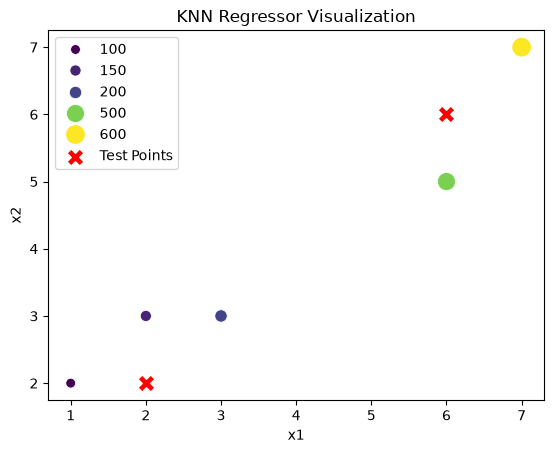

In [5]:
# Visualize Training Data

X_train_df = pd.DataFrame(X_train, columns=["x1", "x2"])

X_train_df["price"] = y_train

sns.scatterplot(
    data=X_train_df,
    x="x1",
    y="x2",
    hue="price",
    size="price",
    palette="viridis",
    sizes=(50, 200)
)

# Visualize Test Points

X_test_df = pd.DataFrame(X_test, columns=["x1", "x2"])

sns.scatterplot(
    data=X_test_df,
    x="x1",
    y="x2",
    color="red",
    marker="X",
    s=150,
    label="Test Points"
)

plt.title("KNN Regressor Visualization")
plt.show()